# Ring analysis around charcoal kilns: example

This notebook shows how to use the two scripts:

- `kiln_ring_analysis.py`: samples a raster along radial transects around every kiln and computes a mean and median per distance ring.
- `plot_kiln_rings.py`: draws the three-panel figure from the results.

Both are used the same way: you pass a dict with the parameters you want to change, and everything you leave out falls back to the `DEFAULTS` at the top of each file.

## 1. Setup

Save this notebook in the same folder as the two `.py` files. If it lives somewhere else, uncomment the `sys.path` line and put in the folder that contains the scripts.

`autoreload` makes the notebook pick up changes to the `.py` files without restarting the kernel.

In [5]:
%load_ext autoreload
%autoreload 2

from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Available parameters

These are all the keys you can put in the parameter dict, with their default values. Any other key raises an error, so typos are caught.

In [6]:
ANALYSIS_DEFAULTS

{'gpkg': 'kohlmeiler_2056.gpkg',
 'id_column': 'ID_PAROLINI',
 'tif': 'merged_dem.tif',
 'band': 1,
 'rings': [(0, 6), (6, 12), (12, 18), (18, 24)],
 'n_rays': 16,
 'step': 1,
 'weighted': False,
 'include_centre': False,
 'min_valid': 0.9,
 'summary_of': 'mean',
 'out_dir': '.',
 'out_prefix': None,
 'save': True,
 'verbose': True}

In [7]:
PLOT_DEFAULTS

{'rings_csv': 'merged_dem_rings.csv',
 'value': 'mean',
 'y_label': 'Canopy height (m)',
 'color': '#2f6db3',
 'out_png': None,
 'save': True,
 'dpi': 200,
 'figsize': (16, 5.2),
 'show': True,
 'seed': 0}

| Key | Meaning |
|---|---|
| `gpkg` | GeoPackage with the kiln points |
| `id_column` | Column that identifies each kiln |
| `tif` | Raster to analyse |
| `band` | Band number of the raster |
| `rings` | List of `(inner, outer)` distances in metres, from inside to outside |
| `n_rays` | Number of directions, evenly spread over 360° |
| `step` | Spacing of samples along each ray, in metres |
| `weighted` | `True`: weight samples by distance (area mean); `False`: all samples count equally |
| `include_centre` | Whether the value at the kiln itself is part of the first ring |
| `min_valid` | A ring is left empty if less than this share of its samples has data |
| `summary_of` | Per-kiln value used in the overview: `"mean"` or `"median"` |
| `out_dir` | Folder for the output files |
| `out_prefix` | File name prefix (`None` = raster name) |
| `save` | Write the output files |
| `verbose` | Print the overview |

File paths are relative to the folder this notebook is in.

## 3. Run the analysis

Only list what you want to change from the defaults.

In [8]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 16,
    "step": 1,
    "weighted": True,
    "out_dir": "results",
}

out = kiln_ring_analysis(params)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 24 m
Weighted:      True
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples

Overview across all kilns (each kiln = one ring mean, weighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.03    5.87     6.07     6.04
mean     6.64    6.44     6.39     6.54
std      3.74    3.57     3.49     3.37
min      0.00    0.00     0.00     0.21
25%      4.62    4.59     4.28     4.74
50%      6.03    5.87     6.07     6.04
75%      8.73    8.56     7.46     7.86
max     19.22   16.17    17.58    17.04

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kilns [

## 4. Look at the results

`out` is a dict:

- `out["summary"]`: overview across all kilns, one column per ring
- `out["rings"]`: one row per kiln with mean, median, number of samples and valid share per ring
- `out["samples"]`: every single sample (kiln, ray, distance, ring, value, ...)
- `out["files"]`: paths of the written files
- `out["params"]`: the full parameter set that was used

In [9]:
out["summary"].round(2)

,0-6 m,6-12 m,12-18 m,18-24 m
count,79.00,79.00,79.00,79.00
median,6.03,5.87,6.07,6.04
mean,6.64,6.44,6.39,6.54
std,3.74,3.57,3.49,3.37
min,0.00,0.00,0.00,0.21
25%,4.62,4.59,4.28,4.74
50%,6.03,5.87,6.07,6.04
75%,8.73,8.56,7.46,7.86
max,19.22,16.17,17.58,17.04


In [10]:
out["rings"].head()

,x,y,mean_0_6,median_0_6,n_0_6,valid_0_6,mean_6_12,median_6_12,n_6_12,valid_6_12,mean_12_18,median_12_18,n_12_18,valid_12_18,mean_18_24,median_18_24,n_18_24,valid_18_24
kiln_id,,,,,,,,,,,,,,,,,,
1,2.808165e+06,1.171932e+06,9.432143,7.92,96,1.000000,9.746349,8.27,96,1.000000,11.166579,10.04,96,1.000000,13.902350,13.94,96,1.000000
2,2.808257e+06,1.171884e+06,0.001607,0.00,96,1.000000,0.018322,0.00,96,1.000000,0.268394,0.00,96,1.000000,2.241720,0.00,96,1.000000
3,2.808341e+06,1.171832e+06,0.000000,0.00,96,0.989583,0.000000,0.00,96,0.989583,0.120502,0.00,96,0.947917,1.847584,0.00,96,0.989583
4,2.808323e+06,1.171930e+06,0.000000,0.00,96,1.000000,0.000000,0.00,96,0.989583,0.057422,0.00,96,0.989583,0.643678,0.00,96,0.979167
5,2.808301e+06,1.172105e+06,0.000000,0.00,96,1.000000,0.000000,0.00,96,1.000000,0.000000,0.00,96,1.000000,0.213733,0.00,96,0.968750


In [11]:
out["samples"].head()

,kiln_id,kiln_x,kiln_y,ray,bearing,distance,ring,ring_index,x,y,value,valid,weight
0,1,2.808165e+06,1.171932e+06,0,0.0,1.0,0-6,0,2.808165e+06,1.171933e+06,9.82,True,1.0
1,1,2.808165e+06,1.171932e+06,0,0.0,2.0,0-6,0,2.808165e+06,1.171934e+06,7.00,True,2.0
2,1,2.808165e+06,1.171932e+06,0,0.0,3.0,0-6,0,2.808165e+06,1.171935e+06,2.14,True,3.0
3,1,2.808165e+06,1.171932e+06,0,0.0,4.0,0-6,0,2.808165e+06,1.171936e+06,2.18,True,4.0
4,1,2.808165e+06,1.171932e+06,0,0.0,5.0,0-6,0,2.808165e+06,1.171937e+06,4.71,True,5.0


In [12]:
out["files"]

{'rings': PosixPath('results/merged_dem_rings.csv'),
 'summary': PosixPath('results/merged_dem_summary.csv'),
 'samples_csv': PosixPath('results/merged_dem_samples.csv'),
 'samples_gpkg': PosixPath('results/merged_dem_samples.gpkg')}

## 5. Plot

Pass the path of the `_rings.csv` file that the analysis wrote. Assign the result to a variable (`fig = ...`) so the figure is not shown twice.

80 kilns, rings: 0-6 m, 6-12 m, 12-18 m, 18-24 m
Kilns with at least one empty ring: 1
Saved results/merged_dem_rings_mean_plot.png


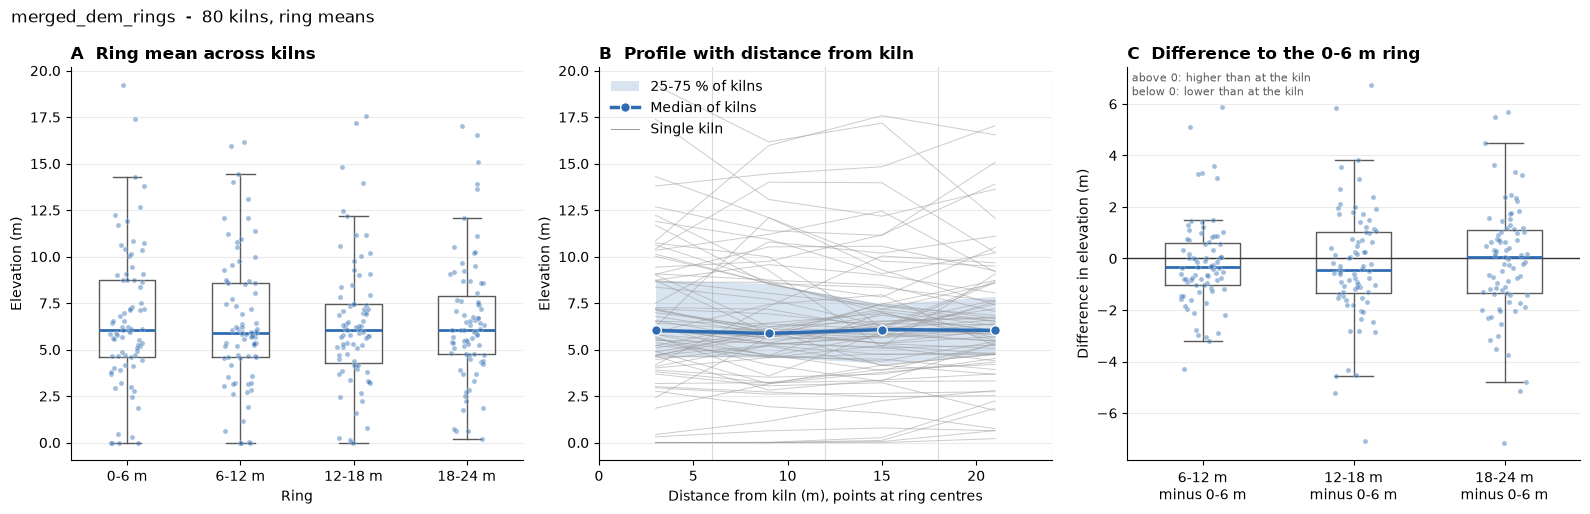

In [13]:
fig = plot_kiln_rings({
    "rings_csv": out["files"]["rings"],
    "value": "mean",
    "y_label": "Elevation (m)",
})

## 6. Several rasters in a loop

`{**params, "tif": tif}` copies the parameters from above and swaps only the raster. Outputs are named after each raster, so nothing is overwritten. Replace the file names and y-axis labels with your own.

80 kilns, rings: 0-6 m, 6-12 m, 12-18 m, 18-24 m
Kilns with at least one empty ring: 1
Saved results/merged_dem_rings_mean_plot.png


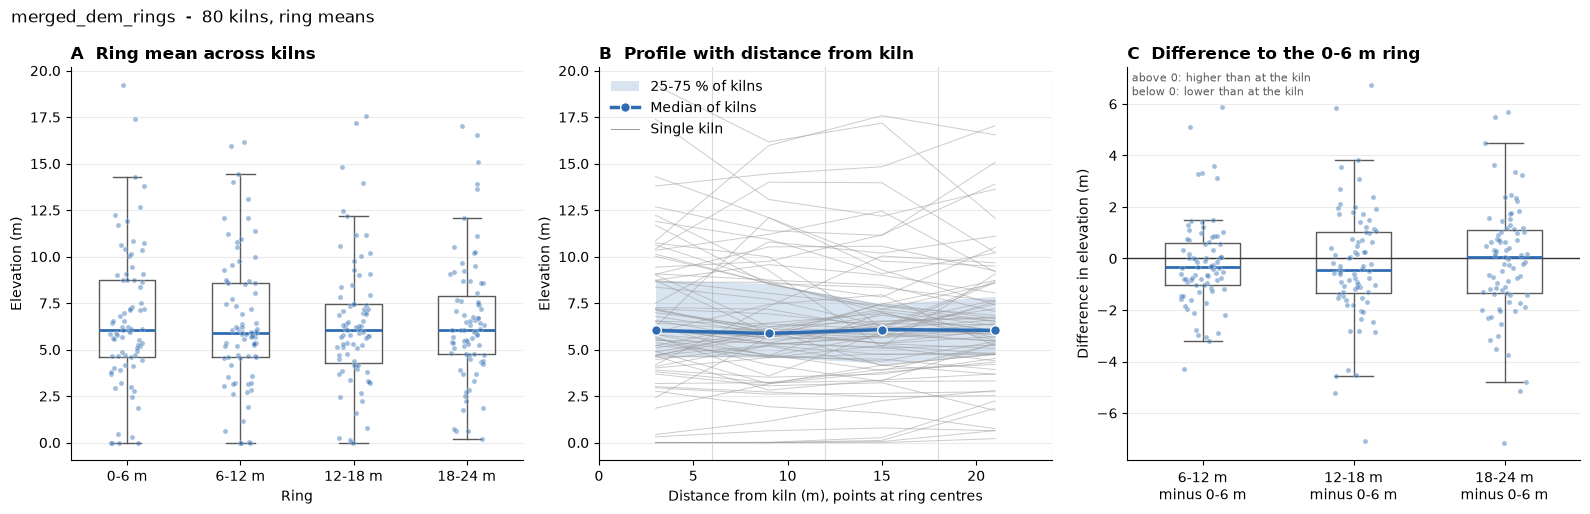

In [14]:
rasters = {
    "merged_dem.tif": "Elevation (m)",
    # "canopy_height.tif": "Canopy height (m)",
}

results = {}
for tif, y_label in rasters.items():
    results[tif] = kiln_ring_analysis({**params, "tif": tif, "verbose": False})
    fig = plot_kiln_rings({"rings_csv": results[tif]["files"]["rings"], "y_label": y_label})

## 7. Comparing settings

The same idea works for testing a setting, for example weighted against unweighted. Here nothing is saved; only the summaries are compared.

In [15]:
import pandas as pd

compare = {}
for w in (False, True):
    res = kiln_ring_analysis({**params, "weighted": w, "save": False, "verbose": False})
    compare["weighted" if w else "unweighted"] = res["summary"].loc["median"]

pd.DataFrame(compare).round(2)

,unweighted,weighted
0-6 m,6.20,6.03
6-12 m,5.93,5.87
12-18 m,6.14,6.07
18-24 m,6.06,6.04
